In [369]:
!uv pip install opencv-python numpy matplotlib

Using Python 3.12.3 environment at: /home/aesthetic/code/badminton-analysis/.venv
Audited 3 packages in 1ms


In [370]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

## Court Detection Strategies
Objective: determine where the court and pole are, and bound them according to lines with dimensions matching real court dimensions in 3d space

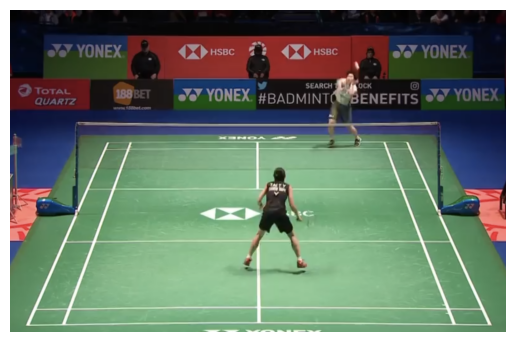

In [371]:
frame = cv2.imread('../test_data/shot2.png')
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Bright Spot Extraction

Use the two-sided stripe test from MonoTrack's released [pixel detector](https://github.com/jhwang7628/monotrack/blob/main/court-detection/CourtLinePixelDetector.cpp#L126-L159): a candidate must reach intensity 80 and exceed both opposite samples by more than 20, either left/right or above/below, at an offset of 4 pixels. Border pixels without all four neighbours are excluded.

The released implementation actually extracts channel zero of the original frame, despite naming it luminance. For our OpenCV BGR input, this is **blue**. We use that channel here to reproduce the candidate test. White can differ from a red or green surface in blue even when HSV value barely changes. To compare a grayscale intensity instead, replace the channel-selection line with `cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)`.

`sample_offset` controls the stripe width scale: if it is too small, side samples remain inside a wide marking; if too large, they reach unrelated surfaces. Thresholds are on a 0–255 scale. Convert to float before subtraction to avoid unsigned-byte wraparound. No HSV saturation or blurred-background gate is applied at this stage. The next structure-tensor cell still uses HSV value, so this experiment changes candidate extraction only.


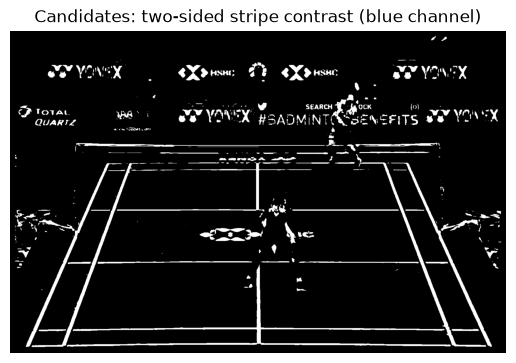

In [372]:
# Keep HSV available for the following structure-tensor cell.
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

intensity_threshold = 80
contrast_threshold = 20
sample_offset = 16

# Match the released detector's channel-zero extraction (blue for BGR frames).
stripe_intensity = frame[:, :, 0].astype(np.float32)
height, width = stripe_intensity.shape
t = sample_offset
if not (1 <= t and 2 * t < min(height, width)):
    raise ValueError("sample_offset must leave a non-empty interior and be at least 1.")

# Compare only pixels with valid neighbours; do not wrap at image borders.
centre = stripe_intensity[t:-t, t:-t]
left = stripe_intensity[t:-t, :-2 * t]
right = stripe_intensity[t:-t, 2 * t:]
top = stripe_intensity[:-2 * t, t:-t]
bottom = stripe_intensity[2 * t:, t:-t]

across_x = ((centre - left) > contrast_threshold) & ((centre - right) > contrast_threshold)
across_y = ((centre - top) > contrast_threshold) & ((centre - bottom) > contrast_threshold)

candidates = np.zeros((height, width), dtype=bool)
candidates[t:-t, t:-t] = (centre >= intensity_threshold) & (across_x | across_y)

plt.title("Candidates: two-sided stripe contrast (blue channel)")
plt.axis("off")
plt.imshow(candidates, cmap="gray")
plt.show()


## Line Filtering

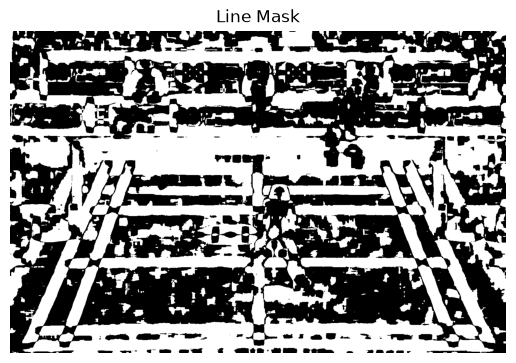

In [373]:
v = hsv[:, :, 2].astype(np.float32)

image = v.astype(np.float32)

# 1. Smooth image to reduce noise
image = cv2.GaussianBlur(image, (5, 5), 0)

# 2. Compute image gradients
dx = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=3)
dy = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=3)

# 3. Compute structure tensor components
window = (21, 21)

Jxx = cv2.boxFilter(dx * dx, -1, window)
Jxy = cv2.boxFilter(dx * dy, -1, window)
Jyy = cv2.boxFilter(dy * dy, -1, window)

# 4. Compute the two eigenvalues
discriminant = np.sqrt(
    (Jxx - Jyy)**2 + 4 * Jxy**2
)

lambda1 = (Jxx + Jyy + discriminant) / 2
lambda2 = (Jxx + Jyy - discriminant) / 2

# 5. Select linear structures
linear = lambda1 > 8 * np.maximum(lambda2, 0)

# 6. Keep only existing candidate pixels
final_mask = (linear).astype(np.uint8) * 255

plt.title("Line Mask")
plt.imshow(final_mask, cmap="gray")
plt.axis("off")
plt.show()

## Extracted Lines

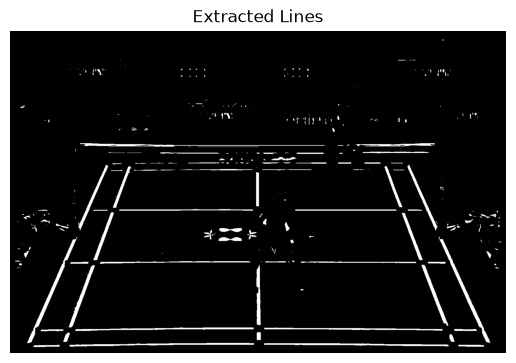

In [374]:
extracted_lines = candidates & linear

plt.title("Extracted Lines")
plt.imshow(extracted_lines, cmap="gray")
plt.axis("off")
plt.show()

## Line Generation

In [375]:
mask = extracted_lines.astype(np.uint8) * 255

raw_lines = cv2.HoughLines(
    mask,
    rho=1,
    theta=np.pi / 1080,
    threshold=200,
)

### Raw Hough Lines

Visualize every peak returned by `cv2.HoughLines` before duplicate suppression and partitioning. Each `(rho, theta)` represents an infinite line; the plot clips it to the frame. Thin, transparent strokes make overlapping detections visible. If no peaks are returned, the overlay shows the original frame with a count of zero.


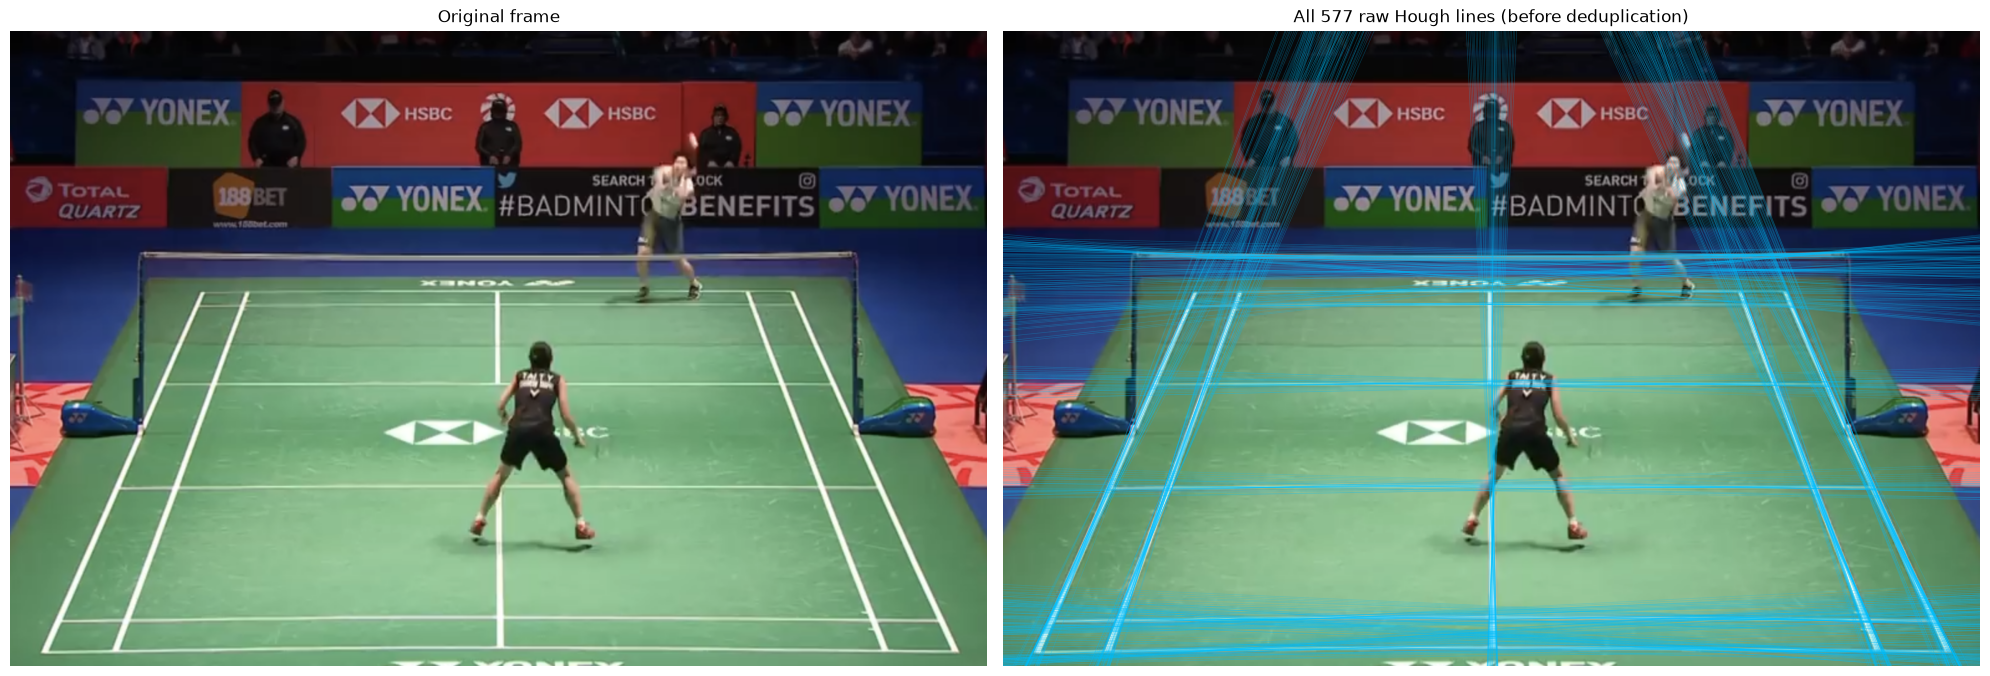

In [376]:
from matplotlib.collections import LineCollection

# Draw every Hough peak, with no count limit or duplicate suppression.
hough_parameters = (
    np.empty((0, 2), dtype=np.float32)
    if raw_lines is None else np.asarray(raw_lines).reshape(-1, 2)
)
height, width = frame.shape[:2]
line_extent = 2 * np.hypot(width, height)
rho = hough_parameters[:, 0]
theta = hough_parameters[:, 1]
normals = np.column_stack([np.cos(theta), np.sin(theta)])
directions = np.column_stack([-np.sin(theta), np.cos(theta)])
origins = rho[:, None] * normals
hough_segments = np.stack([
    origins - line_extent * directions,
    origins + line_extent * directions,
], axis=1)

# One collection keeps rendering responsive even with thousands of lines.
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for axis in axes:
    axis.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axis.set_xlim(0, width)
    axis.set_ylim(height, 0)
    axis.axis("off")
axes[0].set_title("Original frame")
axes[1].add_collection(LineCollection(
    hough_segments, colors="deepskyblue", linewidths=0.5, alpha=0.25,
))
axes[1].set_title(f"All {len(hough_parameters):,} raw Hough lines (before deduplication)")
plt.tight_layout()
plt.show()


## Line Partitioning

Partition the Hough lines into two direction families using the graph weighting from [MonoTrack, section 4.1](https://arxiv.org/html/2204.01899v2#S4.SS1).
Each line is a node. Nearly perpendicular pairs receive large weights, and we seek a partition that maximizes the total weight **between** families.

First suppress nearby Hough peaks: one painted stripe can generate multiple detections. The angle and distance tolerances below control how aggressively these detections are merged. The distance is measured at the image centre, after aligning the line normals to handle the equivalent representations `(rho, theta)` and `(-rho, theta + pi)`.

`max_lines=40` limits the graph to the first distinct Hough peaks (strongest votes first). Raising it retains weaker candidates but adds clutter and increases the later court-layout search cost. Lowering it can discard real court markings.

The partition uses greedy single-line moves from several reproducible random starts. It finds a local optimum, not a guaranteed global optimum. The families have arbitrary labels; perspective means they need not look exactly horizontal and vertical, or meet at 90 degrees in the image.


In [377]:
def deduplicate_hough_lines(
    raw_lines, image_shape, angle_tolerance_deg=2, distance_tolerance_px=10,
    max_lines=40,
):
    """Return distinct (rho, theta) lines, retaining stronger Hough peaks first."""
    if raw_lines is None:
        raise ValueError("No Hough lines found; inspect the mask and Hough threshold.")

    height, width = image_shape[:2]
    centre = np.array([width / 2, height / 2])
    angle_tolerance = np.deg2rad(angle_tolerance_deg)
    kept = []
    kept_normals = []

    for rho, theta in np.asarray(raw_lines).reshape(-1, 2):
        normal = np.array([np.cos(theta), np.sin(theta)])
        if kept:
            normals = np.asarray(kept_normals)
            alignment = np.where(normals @ normal >= 0, 1.0, -1.0)
            aligned_normals = normals * alignment[:, None]
            aligned_rhos = np.asarray(kept)[:, 0] * alignment
            angles = np.arccos(np.clip(aligned_normals @ normal, -1, 1))
            separation = np.abs(
                (normal - aligned_normals) @ centre - rho + aligned_rhos
            )
            if np.any((angles < angle_tolerance) & (separation < distance_tolerance_px)):
                continue

        kept.append((rho, theta))
        kept_normals.append(normal)
        if len(kept) >= max_lines:
            break

    return np.asarray(kept, dtype=np.float64).reshape(-1, 2)


lines = deduplicate_hough_lines(raw_lines, frame.shape)
print(f"Hough peaks: {len(raw_lines)}; retained distinct lines: {len(lines)}")


Hough peaks: 577; retained distinct lines: 40


In [378]:
def partition_hough_lines(lines, epsilon=0.01, n_starts=20, seed=0):
    """Greedily maximize cross-family weights; return two (rho, theta) arrays."""
    lines = np.asarray(lines, dtype=np.float64).reshape(-1, 2)
    if len(lines) < 2:
        raise ValueError("At least two distinct lines are needed for partitioning.")
    if epsilon <= 0 or n_starts < 1:
        raise ValueError("epsilon and n_starts must be positive.")

    # Normal-angle differences also measure line-angle differences.
    # abs(cos(delta)) treats a line as undirected: theta and theta + pi agree.
    theta = lines[:, 1]
    delta = theta[:, None] - theta[None, :]
    angle = np.arccos(np.clip(np.abs(np.cos(delta)), 0, 1))
    weights = 1.0 / (np.abs(angle - np.pi / 2) + epsilon)**2
    np.fill_diagonal(weights, 0.0)

    rng = np.random.default_rng(seed)
    best_score = -np.inf
    best_labels = None

    for _ in range(n_starts):
        labels = rng.integers(0, 2, size=len(lines)).astype(bool)
        while True:
            same_family = labels[:, None] == labels[None, :]
            # Moving i gains its within-family edges and loses its cross-family edges.
            gains = np.sum(weights * np.where(same_family, 1.0, -1.0), axis=1)
            move = int(np.argmax(gains))
            if gains[move] <= 1e-8:
                break
            labels[move] = ~labels[move]

        # Each undirected edge occurs twice in the symmetric weight matrix.
        score = weights[labels[:, None] != labels[None, :]].sum() / 2
        if score > best_score:
            best_score = score
            best_labels = labels.copy()

    return lines[~best_labels], lines[best_labels]


family_a, family_b = partition_hough_lines(lines)
print(f"Family A: {len(family_a)} lines; family B: {len(family_b)} lines")


Family A: 21 lines; family B: 19 lines


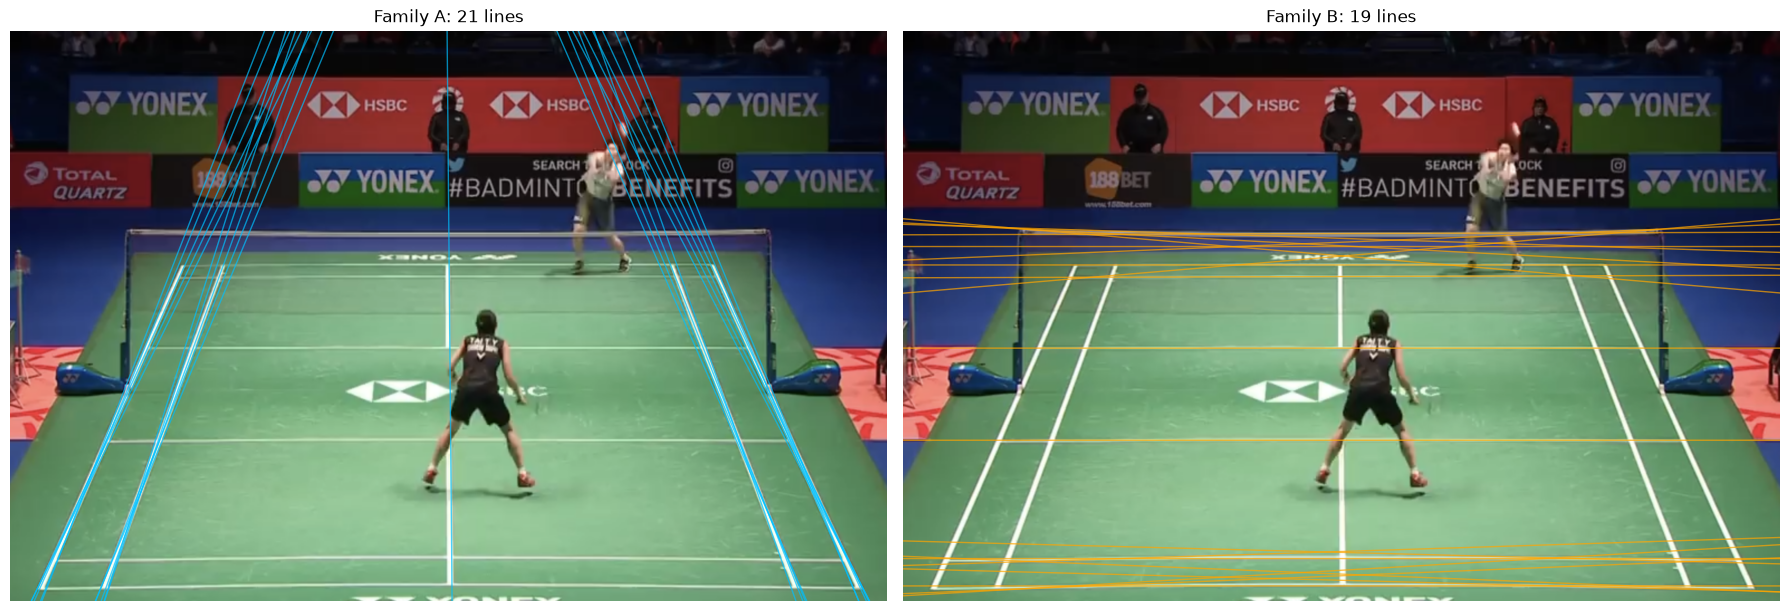

In [379]:
# Inspect the families before using them to search for a court layout.
height, width = frame.shape[:2]
extent = 2 * np.hypot(width, height)
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for axis, family, name, colour in zip(
    axes, [family_a, family_b], ["A", "B"], ["deepskyblue", "orange"]
):
    axis.imshow(frame_rgb)
    for rho, theta in family:
        normal = np.array([np.cos(theta), np.sin(theta)])
        direction = np.array([-np.sin(theta), np.cos(theta)])
        endpoints = rho * normal + np.array([-extent, extent])[:, None] * direction
        axis.plot(endpoints[:, 0], endpoints[:, 1], color=colour, linewidth=1, alpha=0.7)
    axis.set_xlim(0, width)
    axis.set_ylim(height, 0)
    axis.set_title(f"Family {name}: {len(family)} lines")
    axis.axis("off")

plt.tight_layout()
plt.show()


## Court Layout Search

A candidate court must explain the **whole pattern of painted markings**, not just four strong lines. Following the reference-rectangle search described in [MonoTrack, section 4.1](https://arxiv.org/html/2204.01899v2#S4.SS1), choose two lines from each family and intersect them to obtain four candidate corners. A [homography](https://docs.opencv.org/4.x/d9/dab/tutorial_homography.html) maps the flat court template onto those corners, including perspective. Score the projected internal markings as well as its boundaries, and retain the best layout.

This first version assigns the four selected lines to the **outer doubles boundaries**. It assumes the full outer court is visible, all four boundary lines survive detection and partitioning, and the court covers at least 15% of the image. These are explicit search priors, appropriate for the current broadcast frames. It does not yet search internal reference rectangles to recover missing boundaries.

The template below uses metres: width 6.10, length 13.40, singles sidelines 0.46 inside each side, doubles long service lines 0.76 inside each end, and short service lines 1.98 from the net. See the [BWF court diagram, page 2](https://usabadminton.org/wp-content/uploads/2021/05/Section-4.1-Laws-of-Badminton.pdf). We approximate the 40 mm painted markings as thin lines. The centre service line has a gap between the two short service lines. Net tape and posts are above the floor and are not part of this planar template.

For scoring, a distance transform gives the distance from each image pixel to the nearest detected candidate pixel. A projected sample at distance `d` receives support `exp(-0.5 * (d / tolerance_px)**2)`. Samples are evenly spaced along each projected marking; every marking receives equal weight, so long near-camera lines do not dominate shorter distant lines. Missing or occluded pixels lower support without invalidating a whole layout.

- Larger `tolerance_px` accepts less precise alignment; smaller values discriminate closely spaced layouts but penalize Hough localization errors.
- Raising `min_area_fraction` rejects more small false layouts but assumes a larger court in the frame.
- More retained Hough lines increase the chance of retaining the true boundaries, but the search considers `C(len(family_a), 2) * C(len(family_b), 2)` line combinations and two width/length assignments for each valid quadrilateral.

The score is **mask agreement, not a probability or measured accuracy**. This scoring rule is our baseline implementation, not a claimed reproduction of the paper's scoring code. Extra clutter is not directly penalized and can support a false layout. Inspect the overlay and per-marking scores. Because the court template is symmetric, its coordinate orientation is ambiguous; corner indices below follow the template, not guaranteed top-left/near-player labels.


In [380]:
# Court-plane coordinates: x across the court, y along its length (metres).
court_width_m = 6.10
court_length_m = 13.40
court_model_corners = np.float32([
    [0, 0], [court_width_m, 0],
    [court_width_m, court_length_m], [0, court_length_m],
])

court_line_names = [
    "Doubles sideline 1", "Singles sideline 1",
    "Singles sideline 2", "Doubles sideline 2",
    "Back boundary 1", "Doubles long service 1", "Short service 1",
    "Short service 2", "Doubles long service 2", "Back boundary 2",
    "Centre service 1", "Centre service 2",
]
court_model_segments = np.float32(
    [[[x, 0], [x, court_length_m]] for x in [0, 0.46, 5.64, court_width_m]]
    + [[[0, y], [court_width_m, y]] for y in [0, 0.76, 4.72, 8.68, 12.64, court_length_m]]
    + [[[3.05, 0], [3.05, 4.72]], [[3.05, 8.68], [3.05, court_length_m]]]
)


In [381]:
from itertools import combinations


def search_court_layout(
    line_mask, family_a, family_b, model_corners, model_segments,
    tolerance_px=3.0, samples_per_line=80, min_area_fraction=0.15,
):
    """Search outer-boundary hypotheses; return the best court-to-image mapping."""
    if len(family_a) < 2 or len(family_b) < 2:
        raise ValueError("Court search needs at least two lines in each family.")
    if tolerance_px <= 0 or samples_per_line < 2:
        raise ValueError("Use positive tolerance and at least two samples per line.")

    line_mask = np.asarray(line_mask, dtype=bool)
    if not line_mask.any():
        raise ValueError("No candidate pixels to score; inspect the line mask first.")
    height, width = line_mask.shape
    # Candidate pixels are zeros, so distances measure proximity to those pixels.
    distances = cv2.distanceTransform((~line_mask).astype(np.uint8), cv2.DIST_L2, 5)
    model_corners = np.asarray(model_corners, dtype=np.float32)
    model_segments = np.asarray(model_segments, dtype=np.float32)
    corners_h = np.column_stack([model_corners, np.ones(4)])
    endpoints_h = np.column_stack([
        model_segments.reshape(-1, 2), np.ones(model_segments.shape[0] * 2),
    ])
    t = np.linspace(0, 1, samples_per_line)[None, :, None]

    def homogeneous_lines(family):
        rho, theta = np.asarray(family).T
        return np.column_stack([np.cos(theta), np.sin(theta), -rho])

    def intersect(first, second):
        point = np.cross(first, second)
        if abs(point[2]) < 1e-8:  # Parallel lines have no finite intersection.
            return None
        return point[:2] / point[2]

    lines_a = homogeneous_lines(family_a)
    lines_b = homogeneous_lines(family_b)
    best = None
    hypotheses_scored = 0

    for a_indices in combinations(range(len(lines_a)), 2):
        a0, a1 = lines_a[list(a_indices)]
        for b_indices in combinations(range(len(lines_b)), 2):
            b0, b1 = lines_b[list(b_indices)]
            points = [intersect(a0, b0), intersect(a0, b1),
                      intersect(a1, b1), intersect(a1, b0)]
            if any(point is None for point in points):
                continue
            quad = np.asarray(points, dtype=np.float32)
            if not np.isfinite(quad).all() or not cv2.isContourConvex(quad):
                continue
            inside = ((quad[:, 0] >= 0) & (quad[:, 0] < width)
                      & (quad[:, 1] >= 0) & (quad[:, 1] < height))
            if not inside.all() or cv2.contourArea(quad) < min_area_fraction * width * height:
                continue

            # Try which family defines width vs length. Reflection and 180-degree
            # alternatives have the same support because this template is symmetric.
            for shift in (0, 1):
                image_corners = np.roll(quad, shift, axis=0)
                H = cv2.getPerspectiveTransform(model_corners, image_corners)
                if not np.isfinite(H).all():
                    continue
                denominators = (corners_h @ H.T)[:, 2]
                if not (np.all(denominators > 1e-8) or np.all(denominators < -1e-8)):
                    continue  # Reject a projection that crosses infinity within the court.

                projected = endpoints_h @ H.T
                segments_px = (projected[:, :2] / projected[:, 2:]).reshape(-1, 2, 2)
                samples = segments_px[:, 0, None] * (1 - t) + segments_px[:, 1, None] * t
                pixels = np.rint(samples).astype(int)
                x, y = pixels[..., 0], pixels[..., 1]
                valid = (x >= 0) & (x < width) & (y >= 0) & (y < height)
                support = np.zeros(x.shape)
                support[valid] = np.exp(
                    -0.5 * (distances[y[valid], x[valid]] / tolerance_px)**2
                )
                line_support = support.mean(axis=1)
                score = float(line_support.mean())
                hypotheses_scored += 1

                if best is None or score > best["score"]:
                    best = {
                        "H_court_to_image": H,
                        "corners_px": image_corners.copy(),
                        "segments_px": segments_px,
                        "score": score,
                        "line_support": line_support,
                        "family_a_indices": a_indices,
                        "family_b_indices": b_indices,
                    }

    if best is None:
        raise ValueError(
            "No valid court hypothesis. Inspect the Hough lines and families; "
            "this search requires four visible outer boundaries and a sufficiently large court."
        )
    best["hypotheses_scored"] = hypotheses_scored
    return best


In [382]:
court_layout = search_court_layout(
    extracted_lines, family_a, family_b,
    court_model_corners, court_model_segments,
    tolerance_px=3.0,
    samples_per_line=80,
    min_area_fraction=0.15,
)

H_court_to_image = court_layout["H_court_to_image"]
court_corners_px = court_layout["corners_px"]

print(f"Scored {court_layout['hypotheses_scored']:,} layout hypotheses")
print(f"Best mask-agreement score: {court_layout['score']:.3f}")
print("Court corners in template order (image pixels):")
print(np.round(court_corners_px, 1))


Scored 22,190 layout hypotheses
Best mask-agreement score: 0.850
Court corners in template order (image pixels):
[[  55.5  995. ]
 [1521.6  995. ]
 [1255.5  420. ]
 [ 313.5  420. ]]


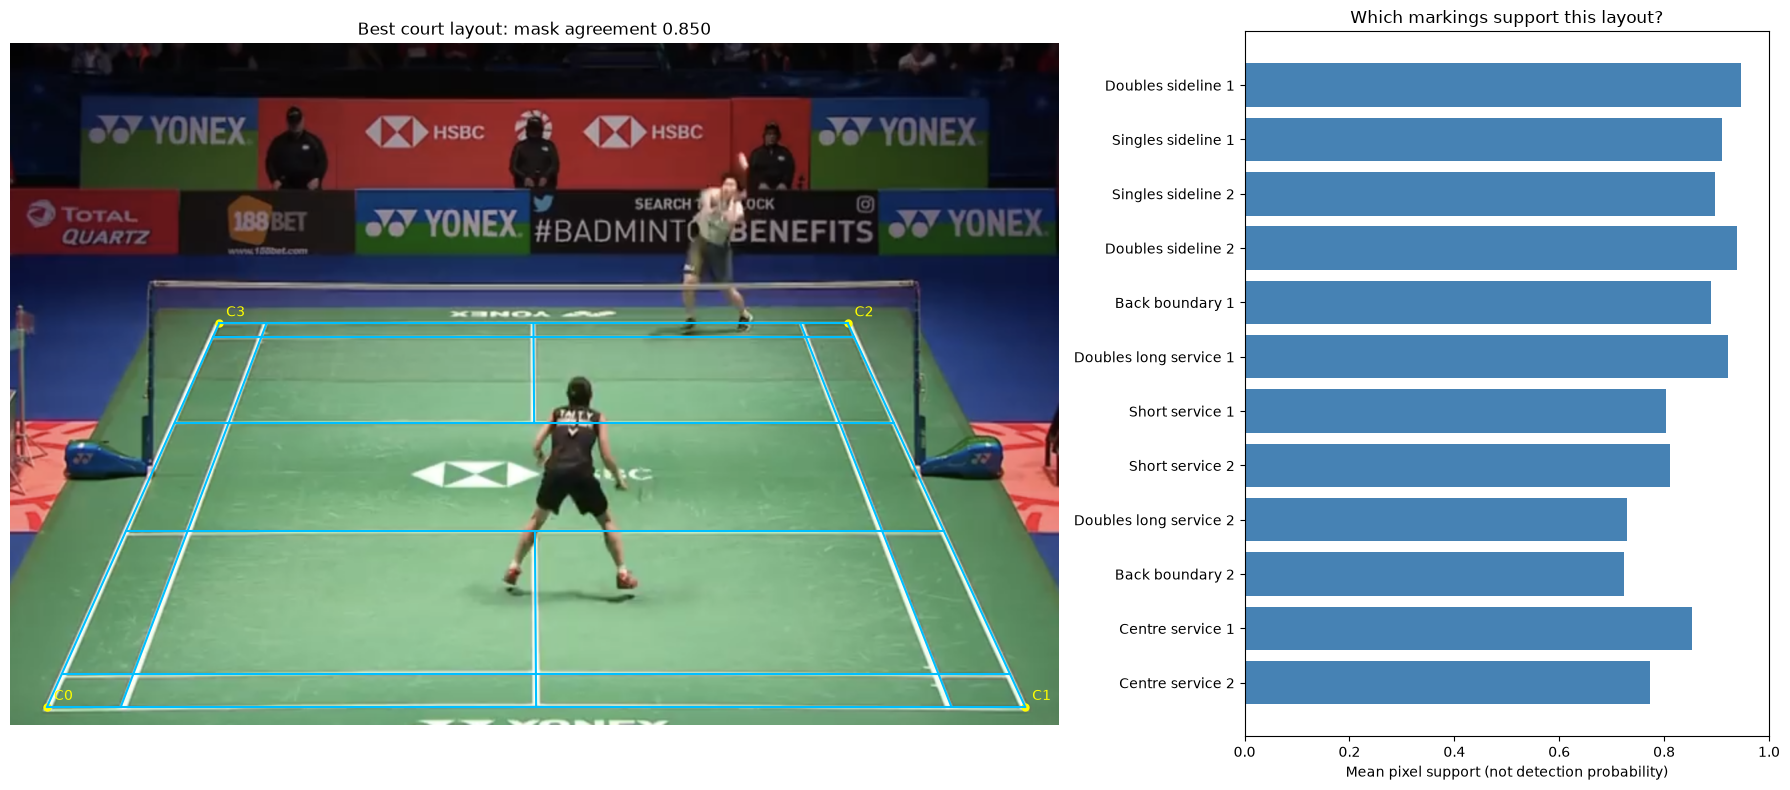

In [383]:
fig, axes = plt.subplots(
    1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [2, 1]}
)
axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
for segment in court_layout["segments_px"]:
    axes[0].plot(segment[:, 0], segment[:, 1], color="deepskyblue", linewidth=1.5)
for index, (x, y) in enumerate(court_corners_px):
    axes[0].scatter(x, y, color="yellow", s=25)
    axes[0].annotate(f"C{index}", (x, y), xytext=(5, 5),
                     textcoords="offset points", color="yellow")
axes[0].set_xlim(0, frame.shape[1])
axes[0].set_ylim(frame.shape[0], 0)
axes[0].set_title(f"Best court layout: mask agreement {court_layout['score']:.3f}")
axes[0].axis("off")

axes[1].barh(court_line_names, court_layout["line_support"], color="steelblue")
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Mean pixel support (not detection probability)")
axes[1].set_title("Which markings support this layout?")
plt.tight_layout()
plt.show()
